In [1]:
import os,sys,time
from glob import glob
import cmocean as cmo
import xarray as xr
from xgcm import Grid
import xesmf
import numpy as np
import matplotlib.pyplot as plt
from mom6_OBC_routines import *
from datetime import datetime
import netCDF4
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

### Inputs

In [2]:
#--- year to generate obc for:
year = '2005'
#--- output dir for unformatted OBC data:
out_obc_no_format_dir = '/glade/derecho/scratch/fredc/glorys012/obc/nwa12_raw/'+year+'/'
#--- output dir for formatted OBC data:
out_obc_format_dir = '/glade/derecho/scratch/fredc/glorys012/obc/nwa12/'+year+'/'
#--- check if outdirs exist/create if not:
make_dir(out_obc_no_format_dir)
make_dir(out_obc_format_dir)

#---mom6 horizontal grid:
target_horizontal_grid = xr.open_dataset('/glade/campaign/cgd/oce/projects/CROCODILE/MOM6/grid/NWA12/ocean_hgrid.nc').rename({'x': 'lon', 'y': 'lat'})

#--- mom6 grid topography file:
topo = xr.open_dataset('/glade/campaign/cgd/oce/projects/CROCODILE/MOM6/grid/NWA12/ocean_topo.nc')

#--- path to data to generate OBCs:
ds_in_path = '/glade/campaign/cgd/oce/projects/CROCODILE/glorys012/GLOBAL/'+year+'/'
ds_in_files = sorted(glob(os.path.join(ds_in_path,f'mercator*.nc')))

#--- var names:
#--- names of variable on source data:
var_names = ['so','thetao','uo','vo','zos']
var_names = ['thetao']
#for renaming after all interpolations are done:
new_var_names = ['salt','temp','u','v','zeta'] 
new_var_names = ['temp']

#---OBC segments:
segs = [1,2,4]
segs_names = ['001','002','004']

### Extract boundary conditions:

In [3]:
drop_var_lst = ['mlotst','bottomT','sithick','siconc','usi','vsi']

In [4]:
lon_min = np.floor(target_horizontal_grid.lon.min()).values - 1
lon_max = np.ceil(target_horizontal_grid.lon.max()).values + 1

In [5]:
lat_min = np.floor(target_horizontal_grid.lat.min()).values - 1
lat_max = np.ceil(target_horizontal_grid.lat.max()).values + 1

In [7]:
for fl in range(1):
    print(ds_in_files[fl])    
    ds_in = xr.open_dataset(ds_in_files[fl],decode_times=False).drop(drop_var_lst).sel(latitude=slice(lat_min,lat_max),longitude=slice(lon_min,lon_max))

    #regrid data:
    regridded = regrid_tracer_obc(ds_in,target_horizontal_grid)

    if fl==0:
        ## depth to thickness:
        zl=ds_in.depth
        zi=0.5*(np.roll(zl,shift=-1)+zl)
        zi[-1]=6500.
        inter=zi
        dz=zi-np.roll(zi,shift=1)
        dz[0]=zi[0]
        inter=dz
        ## segment indices:
        nx, ny = tuple(regridded.dims[d] for d in ['nxp', 'nyp'])
        nz = ds_in.dims['depth']
        ny_segment_001 = np.array(range(ny))
        nx_segment_001 = np.array(range(1))
        ny_segment_002 = np.array(range(1))
        nx_segment_002 = np.array(range(nx))
        ny_segment_004 = np.array(range(1))
        nx_segment_004 = np.array(range(nx))
        nz_segment_001 = np.array(range(nz))
        nz_segment_002 = nz_segment_001.copy()
        nz_segment_004 = nz_segment_001.copy()
        #lat/lon arrays:
        lon_segment_001 = regridded['lon'][:,-1].values
        lat_segment_001 = regridded['lat'][:,-1].values
        lon_segment_002 = regridded['lon'][-1,:].values
        lat_segment_002 = regridded['lat'][-1,:].values
        lon_segment_004 = regridded['lon'][0,:].values
        lat_segment_004 = regridded['lat'][0,:].values
    
    #loop over each variable for each segment/boundary:
    for var in range(len(var_names)):
        for s in range(len(segs)):
            #extract boundary and fill land:
            if var_names[var]=='zos':
                vars()[new_var_names[var]+'_00'+str(segs[s])] = get_segment_fill_zeta(segs[s],regridded[var_names[var]])
            else:
                vars()[new_var_names[var]+'_00'+str(segs[s])] = get_segment_fill(segs[s],regridded[var_names[var]])

            #concatenate:
            if fl == 0:
                vars()['combined_'+new_var_names[var]+'_00'+str(segs[s])] = vars()[new_var_names[var]+'_00'+str(segs[s])]
            else:
                vars()['combined_'+new_var_names[var]+'_00'+str(segs[s])] = xr.concat([vars()['combined_'+new_var_names[var]+'_00'+str(segs[s])],vars()[new_var_names[var]+'_00'+str(segs[s])]],dim='time')

/glade/campaign/cgd/oce/projects/CROCODILE/glorys012/GLOBAL/2005/mercatorglorys12v1_gl12_mean_20050101_R20050105.nc


In [ ]:
### save unformatted data:
#for var in range(len(var_names)):   
#    for s in range(len(segs)):
#        vars()['combined_'+new_var_names[var]+'_00'+str(segs[s])].to_netcdf(out_obc_no_format_dir + 'combined_'+new_var_names[var]+'_00'+str(segs[s])+'_'+year+'.nc')

In [10]:
regridded

<xarray.Dataset>
Dimensions:  (time: 1, nyp: 1561, nxp: 1481, depth: 50)
Coordinates:
  * depth    (depth) float32 0.494 1.541 2.646 ... 4.833e+03 5.275e+03 5.728e+03
  * time     (time) float32 4.821e+05
    lon      (nyp, nxp) float64 -98.0 -97.96 -97.92 ... -37.54 -37.49 -37.45
    lat      (nyp, nxp) float64 5.201 5.201 5.201 5.201 ... 58.37 58.37 58.38
Dimensions without coordinates: nyp, nxp
Data variables:
    zos      (time, nyp, nxp) float64 0.2806 0.2806 0.2806 ... -0.9228 -0.9216
    thetao   (time, depth, nyp, nxp) float64 26.55 26.56 26.57 ... nan nan nan
    so       (time, depth, nyp, nxp) float64 33.82 33.81 33.8 ... nan nan nan
    uo       (time, depth, nyp, nxp) float64 0.05053 0.04558 0.04062 ... nan nan
    vo       (time, depth, nyp, nxp) float64 0.13 0.1198 0.1096 ... nan nan nan
Attributes:
    regrid_method:  bilinear

/glade/work/fredc/miniconda3/envs/sparse/lib/python3.7/site-packages/ipykernel_launcher.py:2: MatplotlibDeprecationWarning: shading='flat' when X and Y have the same dimensions as C is deprecated since 3.3.  Either specify the corners of the quadrilaterals with X and Y, or pass shading='auto', 'nearest' or 'gouraud', or set rcParams['pcolor.shading'].  This will become an error two minor releases later.
  


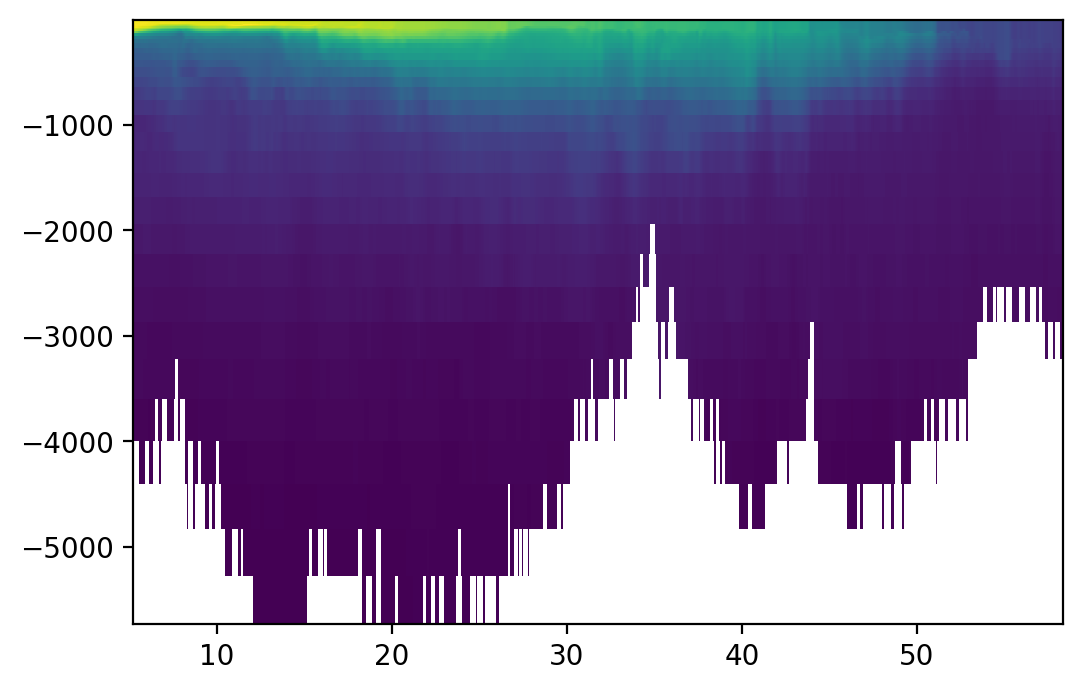

In [32]:
plt.figure(dpi=200)
plt.pcolormesh(regridded.lat[:,-1], -regridded.depth, regridded.thetao[0,:,:,-1])

In [14]:
ds2 = xr.open_dataset('/glade/derecho/scratch/fredc/glorys012/obc/nwa12/2005/combined_temp_001_2005.nc')

In [15]:
ds2

<xarray.Dataset>
Dimensions:              (time: 365, nz_segment_001: 50, ny_segment_001: 1561, nx_segment_001: 1, lon_segment_001: 1561, lat_segment_001: 1561)
Coordinates:
  * lon_segment_001      (lon_segment_001) float64 -36.33 -36.33 ... -37.45
  * lat_segment_001      (lat_segment_001) float64 5.201 5.243 ... 58.35 58.38
  * time                 (time) datetime64[ns] 2005-01-01T12:00:00 ... 2005-1...
  * nz_segment_001       (nz_segment_001) float64 0.0 1.0 2.0 ... 47.0 48.0 49.0
  * ny_segment_001       (ny_segment_001) float64 0.0 1.0 ... 1.559e+03 1.56e+03
  * nx_segment_001       (nx_segment_001) float64 0.0
Data variables:
    temp_segment_001     (time, nz_segment_001, ny_segment_001, nx_segment_001) float64 ...
    dz_temp_segment_001  (time, nz_segment_001, ny_segment_001, nx_segment_001) float32 ...

/glade/work/fredc/miniconda3/envs/sparse/lib/python3.7/site-packages/ipykernel_launcher.py:2: MatplotlibDeprecationWarning: shading='flat' when X and Y have the same dimensions as C is deprecated since 3.3.  Either specify the corners of the quadrilaterals with X and Y, or pass shading='auto', 'nearest' or 'gouraud', or set rcParams['pcolor.shading'].  This will become an error two minor releases later.
  


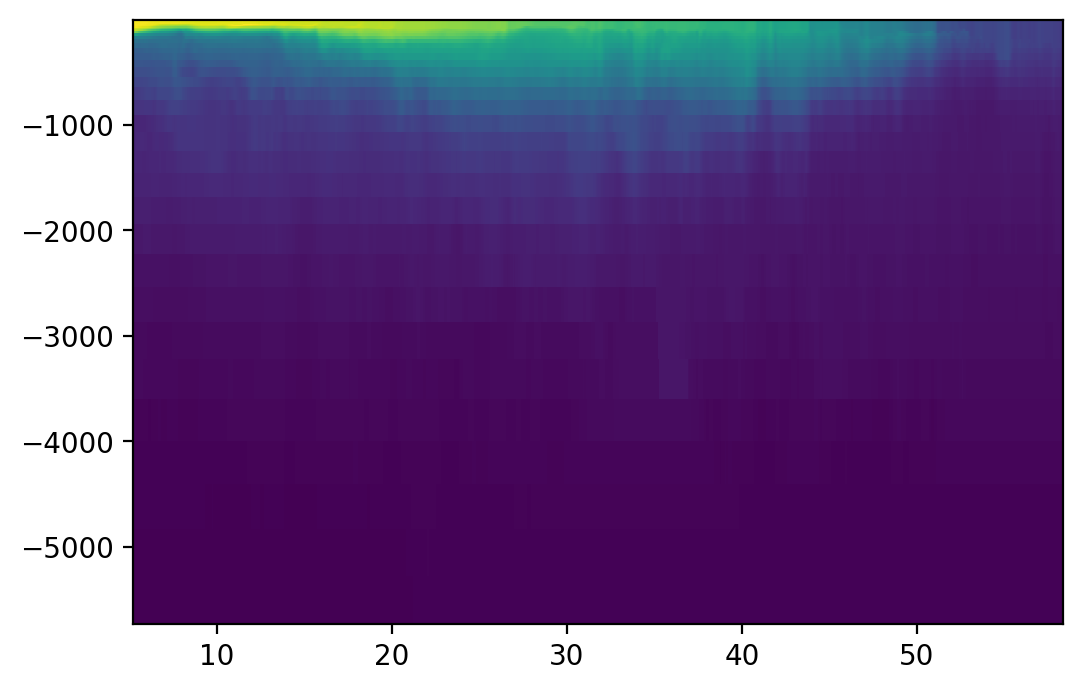

In [31]:
plt.figure(dpi=200)
plt.pcolormesh(ds2.lat_segment_001, -regridded.depth, ds2.temp_segment_001[0,:,:,0])

/glade/work/fredc/miniconda3/envs/sparse/lib/python3.7/site-packages/ipykernel_launcher.py:2: MatplotlibDeprecationWarning: shading='flat' when X and Y have the same dimensions as C is deprecated since 3.3.  Either specify the corners of the quadrilaterals with X and Y, or pass shading='auto', 'nearest' or 'gouraud', or set rcParams['pcolor.shading'].  This will become an error two minor releases later.
  


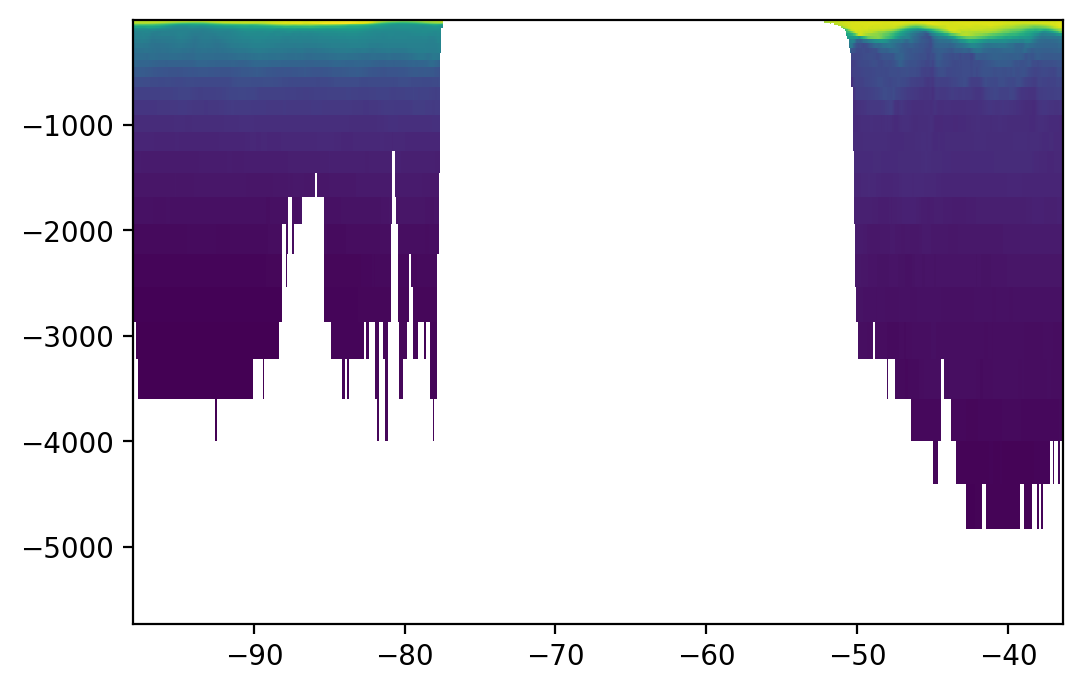

In [30]:
plt.figure(dpi=200)
plt.pcolormesh(regridded.lon[0,:], -regridded.depth, regridded.thetao[0,:,0,:])

In [33]:
ds4 = xr.open_dataset('/glade/derecho/scratch/fredc/glorys012/obc/nwa12/2005/combined_temp_004_2005.nc')

/glade/work/fredc/miniconda3/envs/sparse/lib/python3.7/site-packages/xarray/coding/times.py:527: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates out of range
  dtype = _decode_cf_datetime_dtype(data, units, calendar, self.use_cftime)
/glade/work/fredc/miniconda3/envs/sparse/lib/python3.7/site-packages/xarray/core/indexing.py:419: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates out of range
  return np.asarray(array[self.key], dtype=None)


/glade/work/fredc/miniconda3/envs/sparse/lib/python3.7/site-packages/ipykernel_launcher.py:2: MatplotlibDeprecationWarning: shading='flat' when X and Y have the same dimensions as C is deprecated since 3.3.  Either specify the corners of the quadrilaterals with X and Y, or pass shading='auto', 'nearest' or 'gouraud', or set rcParams['pcolor.shading'].  This will become an error two minor releases later.
  


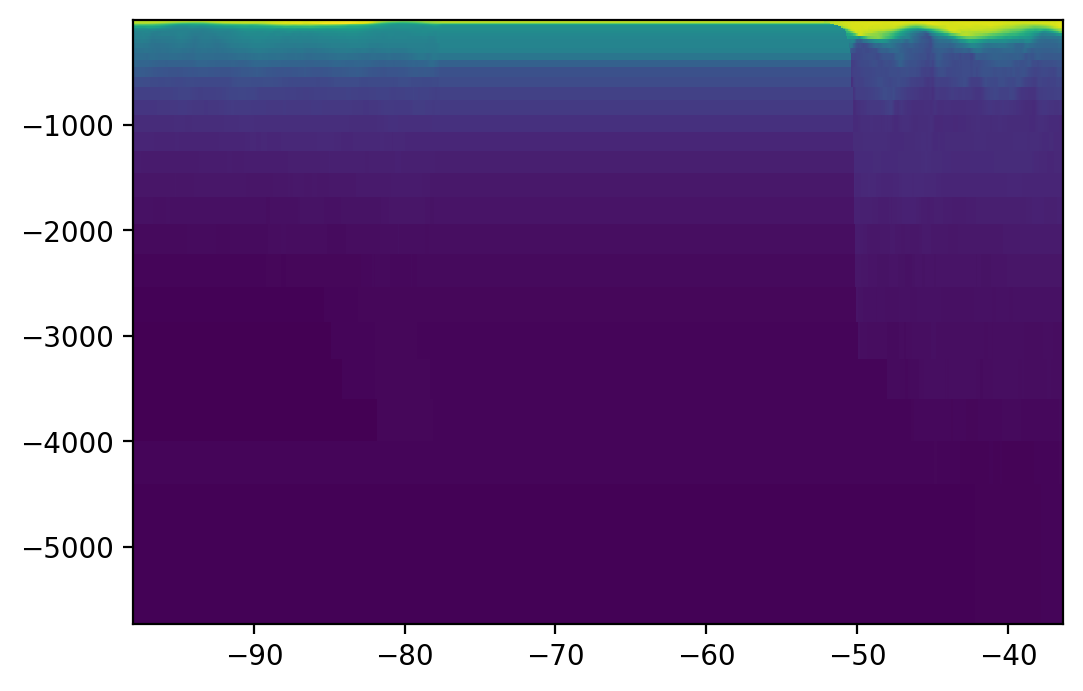

In [38]:
plt.figure(dpi=200)
plt.pcolormesh(ds4.lon_segment_004, -regridded.depth, ds4.temp_segment_004[0,:,0,:])

In [36]:
ds4.temp_segment_004[0,:,0,:]

<xarray.DataArray 'temp_segment_004' (nz_segment_004: 50, nx_segment_004: 1481)>
array([[26.552357, 26.560413, 26.568469, ..., 28.122213, 28.111985, 28.101758],
       [26.552357, 26.560413, 26.568469, ..., 28.122517, 28.112352, 28.102187],
       [26.552357, 26.560413, 26.568469, ..., 28.122946, 28.112566, 28.102187],
       ...,
       [ 1.619048,  1.619048,  1.619048, ...,  1.815976,  1.815976,  1.815976],
       [ 1.619048,  1.619048,  1.619048, ...,  1.815976,  1.815976,  1.815976],
       [ 1.619048,  1.619048,  1.619048, ...,  1.815976,  1.815976,  1.815976]])
Coordinates:
    time            object 3320-01-28 00:00:00
  * nz_segment_004  (nz_segment_004) float64 0.0 1.0 2.0 3.0 ... 47.0 48.0 49.0
    ny_segment_004  float64 0.0
  * nx_segment_004  (nx_segment_004) float64 0.0 1.0 2.0 ... 1.479e+03 1.48e+03

/glade/work/fredc/miniconda3/envs/sparse/lib/python3.7/site-packages/ipykernel_launcher.py:2: MatplotlibDeprecationWarning: shading='flat' when X and Y have the same dimensions as C is deprecated since 3.3.  Either specify the corners of the quadrilaterals with X and Y, or pass shading='auto', 'nearest' or 'gouraud', or set rcParams['pcolor.shading'].  This will become an error two minor releases later.
  


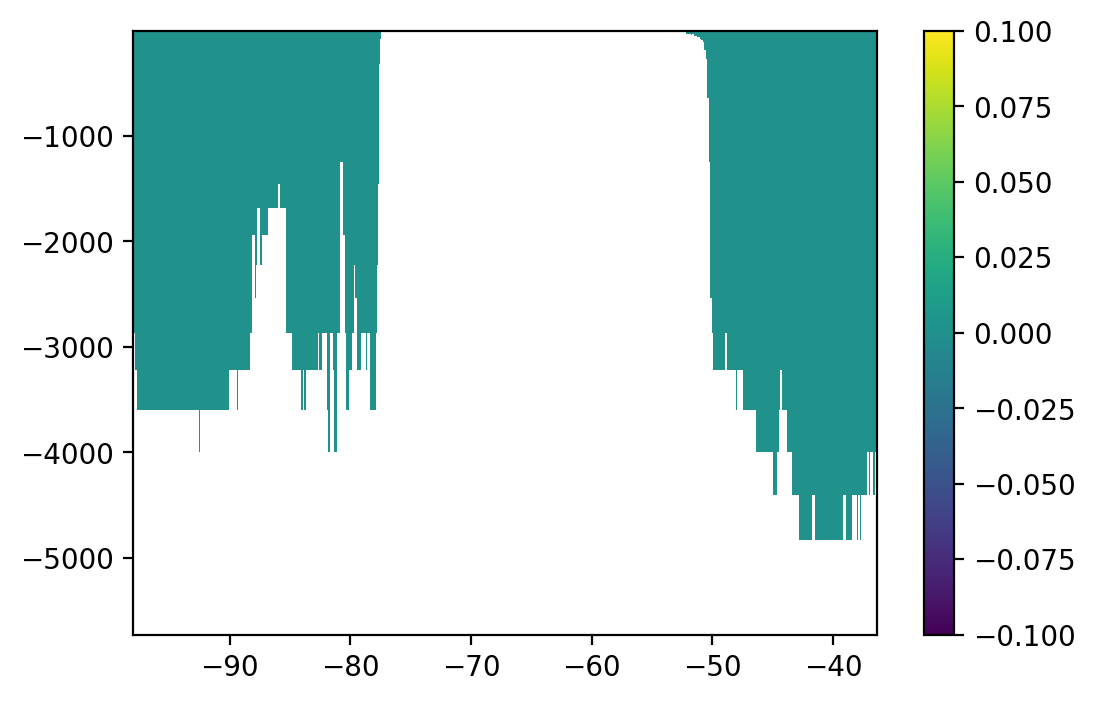

In [44]:
plt.figure(dpi=200)
plt.pcolormesh(ds4.lon_segment_004, -regridded.depth, regridded.thetao[0,:,0,:].values-ds4.temp_segment_004[0,:,0,:].values)
plt.colorbar()